# Eigenfaces & PCA: From Images to Face Recognition

**Goals:** (1) represent images numerically; (2) understand mean subtraction and PCA/SVD; (3) reconstruct images; (4) identify a known person using nearest-neighbor matching; (5) evaluate performance correctly.


---

# 固有顔と主成分分析：画像から顔認識まで

**学習目標：** (1) 画像を数値で表す、(2) 平均の引き算・PCA・SVDを理解する、(3) 顔を再構成する、(4) 最近傍法で登録済みの人物を識別する、(5) 正しい方法で性能を評価する。


## 0. Setup and folder layout
Place this notebook **next to** the unzipped `Yale_Faces_Images` folder. The notebook reads PNGs. Python packages: `numpy`, `matplotlib`, `pillow`, `pandas`, `scikit-learn`, `scipy` (optional).

Example: `Eigenfaces_PCA_Bilingual_Student.ipynb` and `Yale_Faces_Images/person_01/face_01.png`.

---

## 0. 準備とフォルダ構成
このノートブックと解凍した`Yale_Faces_Images`フォルダを**同じ場所**に置きます。PNGファイルを読むので、必要なライブラリ：`numpy`、`matplotlib`、`pillow`、`pandas`、`scikit-learn`（`scipy`は任意）。

In [ ]:
# Run only if your environment lacks the packages. / 必要な場合だけ実行してください。
# %pip install numpy matplotlib pillow pandas scikit-learn scipy

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

DATA_DIR = Path('Yale_Faces_Images')
assert DATA_DIR.is_dir(), 'Unzip Yale_Faces_Images.zip next to this notebook.'
SEED = 42
rng = np.random.default_rng(SEED)
print('Dataset:', DATA_DIR.resolve())

Dataset: /Users/matustanonwong/Desktop/Assistant Professor /Fall Semester 2026/研修１/codes/Week-1/Yale_Faces_Images


## 1. Inspect the image folders
There are **38 folders, one per person**. Each folder contains multiple photos of that person, with different lighting. We will label each person using the folder name, not a real name.


---

## 1. 画像フォルダを確認する
**38個のフォルダがあり、1つのフォルダが1人**に対応します。各フォルダには照明条件の異なる顔画像が複数入っています。実名ではなくフォルダ名を人物ラベルとして使います。


In [2]:
people = sorted(p for p in DATA_DIR.glob('person_*') if p.is_dir())
records = [(p.name, img) for p in people for img in sorted(p.glob('*.png'))]
print(f'People: {len(people)}, images: {len(records)}')
print('First 5 folders:', [(p.name, len(list(p.glob('*.png')))) for p in people[:5]])
assert len(people)==38 and len(records)==2410

People: 38, images: 2410
First 5 folders: [('person_01', 64), ('person_02', 62), ('person_03', 64), ('person_04', 64), ('person_05', 62)]


**Observation:** Each `person_XX` is the ground-truth label for a group of images. The folder structure will let us build a fair train/test split.

---

**確認：** `person_XX`は同じ人物の画像に付ける正解ラベルです。この構造を利用して学習用とテスト用に分割します。

## 2. An image is a matrix of pixels
Each original picture is **192 rows × 168 columns**. Grayscale pixels range from 0 (black) to 255 (white). For PCA, we resize images to **48 × 42** for faster computation, then flatten each image into a vector of length **2,016**. Original PNG files remain unchanged.

**Notation:** height `H`, width `W`, pixel count `D=H×W`.

---

## 2. 画像は画素の行列である
元画像のサイズは**192行 × 168列**です。グレースケール画像の画素値は0（黒）から255（白）です。計算を速くするため、PCAでは**48 × 42**に縮小し、画像を長さ**2,016**のベクトルに変えます。元のPNG画像は変更しません。

**記号：** 高さ`H`、幅`W`、画素数`D=H×W`。

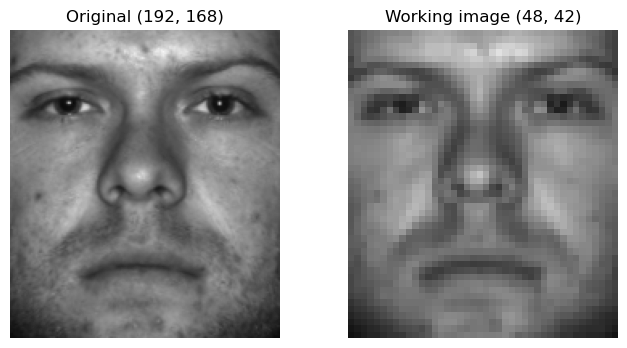

First 12 pixels: [ 84  94 104 113 117 127 132 132 137 137 152 161]
Vector length: 2016


In [3]:
first_img = np.asarray(Image.open(records[0][1]).convert('L'))
H, W = 48, 42
small_img = np.asarray(Image.fromarray(first_img).resize((W,H), Image.Resampling.BILINEAR))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(first_img, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'Original {first_img.shape}')
ax[1].imshow(small_img, cmap='gray', vmin=0, vmax=255); ax[1].set_title(f'Working image {small_img.shape}')
for a in ax: a.axis('off')
plt.show()
print('First 12 pixels:', small_img.flatten()[:12]); print('Vector length:', small_img.size)

**Check:** The vector length is `48 × 42 = 2016`. A face is now a point in a 2,016-dimensional space.

**Question:** Why is it hard to compare or plot 2,016-dimensional points directly?

---

**確認：** ベクトルの長さは`48 × 42 = 2016`です。顔画像は2016次元空間の1点になりました。

**質問：** 2016次元の点をそのまま比較・可視化するのはなぜ難しいのでしょうか？

## 3. Create the data matrix and identity labels
Each **row** of `X_all` is one flattened face image; each entry is scaled to [0,1]. `y_all` stores the person ID. With `N` images and `D` pixels, `X_all` has shape **N × D**. (The textbook stores images as columns; this notebook uses scikit-learn’s rows-as-samples convention.)

---

## 3. データ行列と人物ラベルを作る
`X_all`の**1行**が1枚の顔画像のベクトルに対応し、画素値を[0,1]に変換します。`y_all`に人物IDを保存します。画像数`N`、画素数`D`の場合、`X_all`の形は**N × D**です。（教科書は画像を列に並べますが、このノートブックはscikit-learnに合わせて行に並べます。）

In [4]:
X_all = np.empty((len(records), H*W), dtype=np.float32)
y_all = np.empty(len(records), dtype=np.int32)
for i, (person, path) in enumerate(records):
    im = Image.open(path).convert('L').resize((W,H), Image.Resampling.BILINEAR)
    X_all[i] = np.asarray(im, dtype=np.float32).reshape(-1)/255.0
    y_all[i] = int(person.split('_')[1])
print('X:', X_all.shape, 'labels:', y_all.shape, 'min/max:',X_all.min(),X_all.max())

X: (2410, 2016) labels: (2410,) min/max: 0.0 1.0


## 4. Split images BEFORE learning PCA (avoid data leakage)
For **closed-set recognition**, every person has some registered training photos and some different test photos. We use an **80%/20% stratified split**, preserving each person in both sets. **Only training images are allowed to determine the mean face and PCA basis.**

Later we separately test a person who was never registered.

---

## 4. PCAを学習する前にデータを分割する（情報漏洩を防ぐ）
**既知人物の識別（closed-set）**では、各人物の画像を学習用とテスト用に分けます。**層化80%/20%分割**を使い、すべての人物が両方に入るようにします。**平均顔とPCAの基底は学習画像だけから求めます。**

あとで登録されていない人物も別に検証します。

In [5]:
indices = np.arange(len(y_all))
train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED, stratify=y_all)
X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
print('Training:',len(train_idx),'Test:',len(test_idx))
print('Number of registered persons:',len(np.unique(y_train)))

Training: 1928 Test: 482
Number of registered persons: 38


**Why not train PCA on test images?** That would allow information from the test set to influence the feature extractor and make evaluation overly optimistic.

---

**テスト画像を使ってPCAを学習しない理由：** テストの情報が特徴抽出器に混ざり、評価結果が実際より良く見えてしまうからです。

## 5. Average face and mean subtraction
The **mean face** is the pixel-by-pixel average of training images. To focus on how faces vary, subtract this average from every image.

$$\mu = \frac{1}{N_{\mathrm{train}}}\sum_{i=1}^{N_{\mathrm{train}}} x_i, \qquad x_i^{(c)}=x_i-\mu.$$

**Symbols:** `x_i` = flattened image; `μ` = mean face; `x_i^(c)` = centered image.

---

## 5. 平均顔と平均との差分
**平均顔**は学習画像を画素ごとに平均したものです。顔の変化を調べるため、それぞれの画像から平均顔を引きます。

**記号：** `x_i`＝画像ベクトル、`μ`＝平均顔、`x_i^(c)`＝平均を引いた画像。

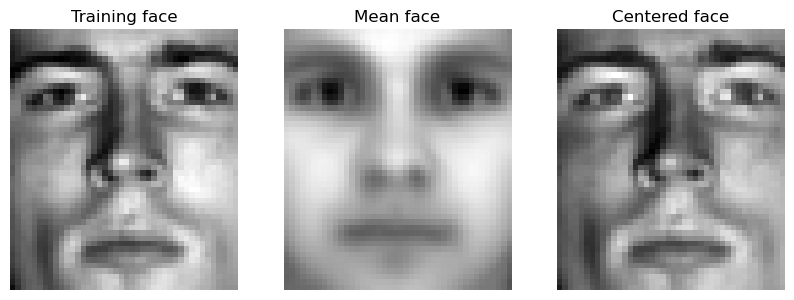

Average of centered values (approx. 0): -1.213072096106771e-06


In [6]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face
fig, axs = plt.subplots(1,3,figsize=(10,4))
for ax, img, title in zip(axs,[X_train[0],mean_face,X_train_centered[0]],['Training face','Mean face','Centered face']):
    ax.imshow(img.reshape(H,W),cmap='gray');ax.set_title(title);ax.axis('off')
plt.show()
print('Average of centered values (approx. 0):',float(X_train_centered.mean()))

**Notice:** The centered face may display negative values; it is not a normal photograph. This is a difference image.

---

**注意：** 平均を引いた画像には負の値も含まれます。通常の写真ではなく、差分画像です。

## 6. Intuition of PCA: find directions of largest variation
Imagine a cloud of points. PCA finds axes along which the cloud varies most. These axes are **principal components (PCs)**. The first PC explains the most variance; the second is perpendicular to the first and explains the next most, and so on.

For faces, the PC directions can be reshaped into images: **Eigenfaces**.

---

## 6. PCAの直感：変化の大きい方向を見つける
点の集まり（点群）を想像しましょう。PCAはデータのばらつきが最も大きい方向を探します。この軸を**主成分（PC）**と呼びます。第1主成分が最も大きな分散を説明し、第2主成分は第1主成分に直交し、次に大きな分散を説明します。

顔画像の主成分を画像の形に戻したものが**固有顔（Eigenfaces）**です。

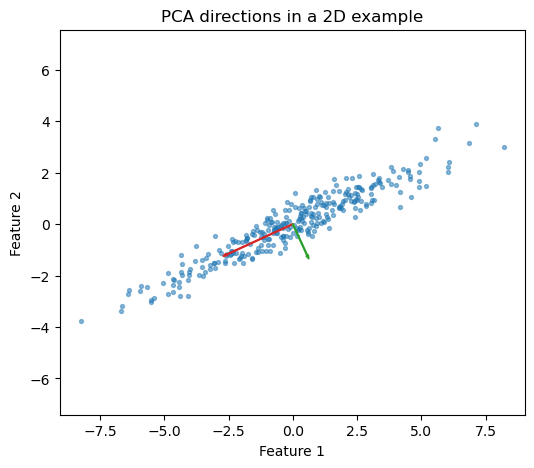

In [7]:
cloud = rng.normal(size=(300,2)) @ np.array([[2.8,1.2],[0.0,0.45]])
cloud -= cloud.mean(axis=0)
_,_,v = np.linalg.svd(cloud,full_matrices=False)
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(cloud[:,0],cloud[:,1],s=8,alpha=.5)
for j,c in enumerate(['tab:red','tab:green']):
    a=v[j]* (3.0 if j==0 else 1.5)
    ax.arrow(0,0,a[0],a[1],width=.035,color=c,length_includes_head=True)
ax.set_title('PCA directions in a 2D example');ax.set_xlabel('Feature 1');ax.set_ylabel('Feature 2');ax.axis('equal');plt.show()

## 7. SVD and Eigenfaces 
For centered images stored as **columns**, the textbook uses SVD:

$$X_c=U\Sigma V^T.$$

The columns of `U` are directions in pixel space (Eigenfaces). In this notebook images are **rows**, so `sklearn.PCA.components_` stores those same pixel-space directions as **rows**. The singular values describe how important the components are. The sign of any Eigenface is arbitrary.

We retain up to **80 components**, enough for demonstrations without computing all 2,016 directions.

---

## 7. SVDと固有顔
教科書は画像を**列**に並べた中心化行列をSVDで分解します：`X_c = UΣVᵀ`。`U`の列は画素空間の方向であり、固有顔として可視化できます。このノートブックは画像を**行**に並べるため、`sklearn.PCA.components_`の**各行**が同じ方向に対応します。特異値は各成分の重要性を示します。固有顔の正負は逆でも問題ありません。

計算時間を短くするため、最大**80成分**を使います。

In [8]:
MAX_K = 80
pca = PCA(n_components=MAX_K, svd_solver='randomized', random_state=SEED)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)
print('Eigenface basis:',pca.components_.shape)
print('Train PCA scores:',Z_train.shape,'Test PCA scores:',Z_test.shape)
print('Mean stored by PCA agrees with our mean:',np.allclose(pca.mean_,mean_face,atol=1e-5))

Eigenface basis: (80, 2016)
Train PCA scores: (1928, 80) Test PCA scores: (482, 80)
Mean stored by PCA agrees with our mean: True


**What is `fit_transform` versus `transform`?** `fit_transform` learns the PCA directions from training images. `transform` projects new images using the directions already learned. Never `fit` again on test data.

---

**`fit_transform`と`transform`の違い：** `fit_transform`は学習画像からPCAの方向を求めます。`transform`は既に求めた方向で新しい画像を射影します。テスト画像では再学習（`fit`）しません。

## 8. Visualize the first Eigenfaces
An Eigenface is **not an actual person face**. It represents a pattern of variation shared by many images. The order follows explained variance, not person identity.

---

## 8. 最初の固有顔を可視化する
固有顔は**実在の人物そのものの顔ではありません**。多くの画像に共通する変化のパターンです。成分の順序は説明分散に対応し、人物IDには対応しません。

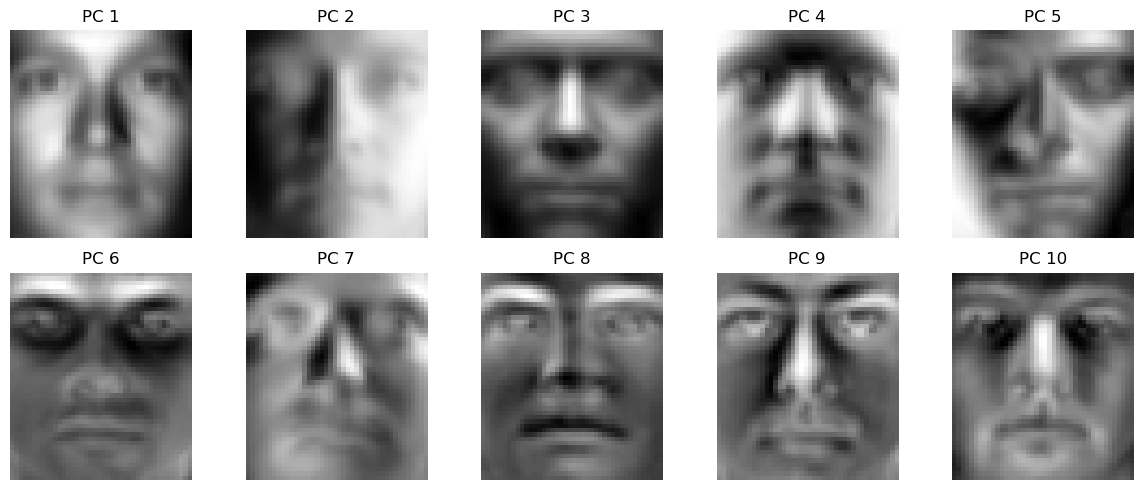

In [9]:
fig,axs=plt.subplots(2,5,figsize=(12,5))
for j,ax in enumerate(axs.flat):
    ax.imshow(pca.components_[j].reshape(H,W),cmap='gray');ax.set_title(f'PC {j+1}');ax.axis('off')
plt.tight_layout();plt.show()

**Think:** Some Eigenfaces look like lighting gradients rather than faces. Why might illumination dominate the data variance?

---

**考えよう：** 顔ではなく照明の変化のように見える固有顔があります。なぜ照明の違いが分散に大きく影響するのでしょうか？

## 9. Explained variance and how many components to keep
The **explained variance ratio** tells us how much variation is represented by each PC. Its cumulative sum tells us how much information the first `k` PCs preserve (measured as training-set variance, not recognition accuracy).

$$R_k=\sum_{j=1}^{k}\frac{\sigma_j^2}{\sum_{\ell}\sigma_{\ell}^2}.$$

Here the denominator is the variance represented in the full data, not just the first 80 components.

---

## 9. 説明分散と主成分数の選び方
**説明分散比**は各主成分がデータのばらつきをどれだけ説明するかを示します。累積値は最初の`k`成分が保持する分散の割合です（**顔認識精度とは異なります**）。

式の分母は最初の80成分だけではなく、全データの分散です。

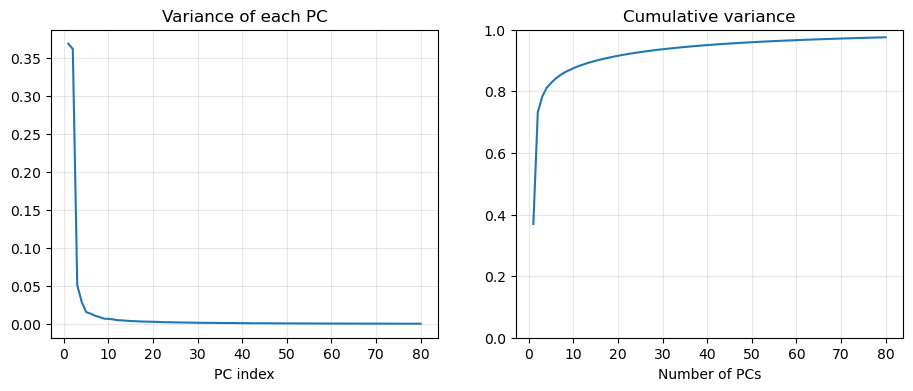

Cumulative variance at k=10, 30, 80: [0.875 0.937 0.975]


In [10]:
cum = np.cumsum(pca.explained_variance_ratio_)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(np.arange(1,MAX_K+1),pca.explained_variance_ratio_);axs[0].set_title('Variance of each PC');axs[0].set_xlabel('PC index')
axs[1].plot(np.arange(1,MAX_K+1),cum);axs[1].set_title('Cumulative variance');axs[1].set_xlabel('Number of PCs');axs[1].set_ylim(0,1)
for ax in axs:ax.grid(alpha=.3)
plt.show()
print('Cumulative variance at k=10, 30, 80:',np.round(cum[[9,29,79]],3))

## 10. PCA projection: from pixels to coordinates
We can replace the full image vector with a much shorter feature vector.

$$z=U_k^T(x-\mu),$$

where `x` is a `D`-pixel face, `μ` is the mean, and `U_k` is the matrix of the first `k` Eigenfaces as **columns**. Then `z` has only `k` values. In code, `pca.transform` performs this step.

---

## 10. PCAへの射影：画素から座標へ
長い画素ベクトルを短い特徴ベクトルに置き換えられます。`x`は`D`個の画素、`μ`は平均顔、`U_k`は最初の`k`個の固有顔を**列**に並べた行列です。`z`の要素数は`k`個です。コードでは`pca.transform`がこの射影を行います。

In [11]:
k=20
one_score = Z_test[0,:k]
print('Original image vector length:',X_test.shape[1]);print('PCA feature length:',len(one_score))
print('First 10 feature values:',np.round(one_score[:10],3))

Original image vector length: 2016
PCA feature length: 20
First 10 feature values: [-3.654 -9.434 -1.347  3.476  0.749 -1.898 -1.142  0.684 -2.343 -2.004]


## 11. Reconstruct a held-out test face
The original image can be approximated by reversing the projection:

$$\hat{x}=\mu+U_k z.$$

The larger `k` is, the more detail may be retained, although reconstruction quality and recognition accuracy are different goals. Test images are never used to learn the mean or Eigenfaces.

---

## 11. テスト用の顔画像を再構成する
射影を逆方向に使うと元画像を近似できます。`k`が大きいほど詳細を保てることがありますが、再構成の品質と顔認識精度は別の目的です。テスト画像から平均顔や固有顔を学習しません。

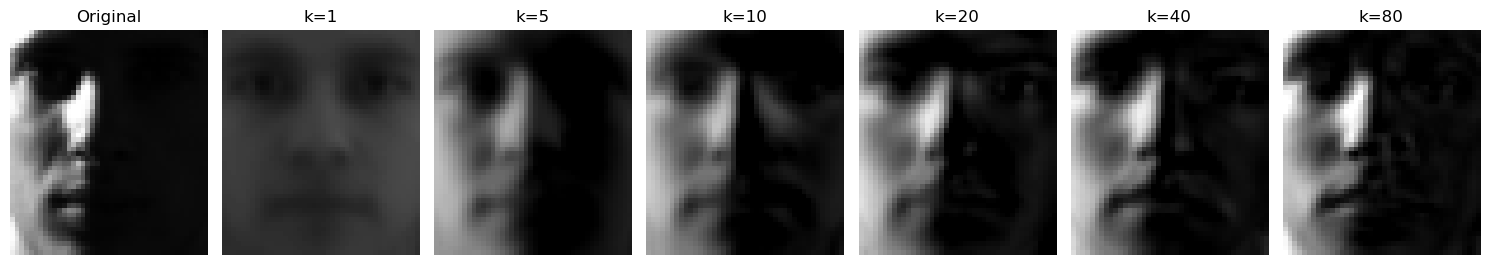

In [12]:
t=0
ks=[1,5,10,20,40,80]
fig,axs=plt.subplots(1,len(ks)+1,figsize=(15,3))
axs[0].imshow(X_test[t].reshape(H,W),cmap='gray',vmin=0,vmax=1);axs[0].set_title('Original')
for j,k in enumerate(ks,1):
    rec=pca.mean_+Z_test[t,:k] @ pca.components_[:k]
    axs[j].imshow(np.clip(rec.reshape(H,W),0,1),cmap='gray',vmin=0,vmax=1);axs[j].set_title(f'k={k}')
for a in axs:a.axis('off')
plt.tight_layout();plt.show()

## 12. Measure reconstruction error (MSE)
**Mean squared error (MSE)** compares pixel values between a real image and its reconstruction. Smaller MSE means better reconstruction.

$$\mathrm{MSE}(x,\hat x)=\frac{1}{D}\sum_{p=1}^D(x_p-\hat{x}_p)^2.$$

This measures pixel similarity, **not** whether the identity is predicted correctly.

---

## 12. 再構成誤差（MSE）を測る
**平均二乗誤差（MSE）**は元画像と再構成画像の各画素値を比較します。MSEが小さいほど再構成が正確です。ただし**人物を正しく識別できたか**を示す値ではありません。

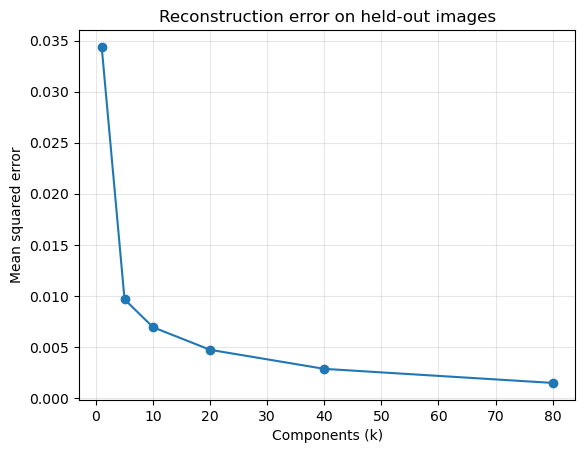

 k  test_MSE
 1  0.034379
 5  0.009659
10  0.006924
20  0.004717
40  0.002851
80  0.001474


In [13]:
k_values=[1,5,10,20,40,80]
mse=[]
for k in k_values:
    recon=pca.mean_+Z_test[:,:k] @ pca.components_[:k]
    mse.append(np.mean((X_test-recon)**2))
plt.plot(k_values,mse,'o-');plt.xlabel('Components (k)');plt.ylabel('Mean squared error');plt.title('Reconstruction error on held-out images');plt.grid(alpha=.3);plt.show()
print(pd.DataFrame({'k':k_values,'test_MSE':mse}).to_string(index=False))

## 13. Visualize the PCA feature space
A 2D scatterplot can display only two selected components. Points that belong to the same person may cluster, but lighting also changes their positions. This is an exploratory visualization, **not a recognition score**.

We use PC5 and PC6, similar to the textbook example.

---

## 13. PCA特徴空間を可視化する
2次元散布図では2つの主成分だけを表示します。同じ人物の点が近くに集まることもありますが、照明でも点の位置が変わります。これは探索的な可視化であり、**顔認識の精度ではありません**。

教科書の例に近い第5・第6主成分を使います。

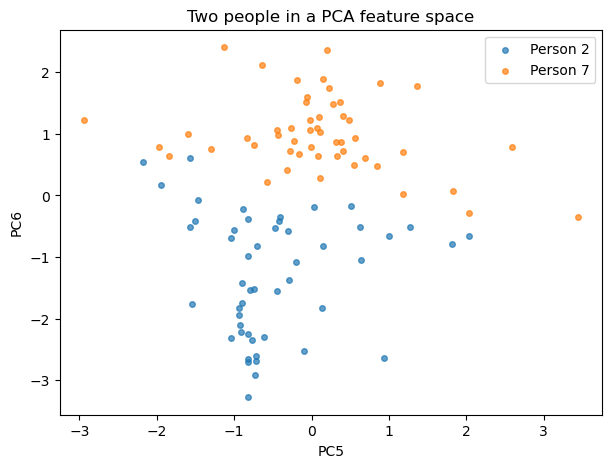

In [14]:
fig,ax=plt.subplots(figsize=(7,5))
for person in [2,7]:
    s=y_train==person
    ax.scatter(Z_train[s,4],Z_train[s,5],label=f'Person {person}',alpha=.7,s=16)
ax.set_xlabel('PC5');ax.set_ylabel('PC6');ax.legend();ax.set_title('Two people in a PCA feature space');plt.show()

## 14. NEW: Recognize a registered person with nearest neighbors
**Recognition pipeline:** ① project a test face into the **same** PCA space; ② compare its feature vector to registered training images; ③ predict the label of the closest one.

$$i^*=\arg\min_i\lVert z_{\mathrm{test}}-z_i\rVert_2.$$

This is **1-nearest neighbor (1-NN)**. In this baseline, every test face is forced to match one registered identity; unknown-person rejection comes later.

---

## 14. 追加：最近傍法で登録済みの人物を識別する
**顔認識の手順：** ① テスト画像を学習と**同じ**PCA空間へ射影する、② 登録画像の特徴ベクトルとの距離を計算する、③ 最も近い画像の人物ラベルを予測する。

これは**1最近傍法（1-NN）**です。ここでは必ず登録済みの誰かに分類します。未登録人物の拒否はあとで扱います。

In [22]:
k=80
clf=KNeighborsClassifier(n_neighbors=1,metric='euclidean')
clf.fit(Z_train[:,:k],y_train)
y_pred=clf.predict(Z_test[:,:k])
print('Held-out recognition accuracy:',round(accuracy_score(y_test,y_pred),3))
print('Example labels — true:',y_test[:10],'predicted:',y_pred[:10])

Held-out recognition accuracy: 0.664
Example labels — true: [24 15 10 10 38  3  9 30 18 16] predicted: [17 15 10  6 38  3  9 28 18  7]


**Interpretation:** If the classifier predicts `person_07`, it means that the nearest registered face has that label. It does **not** prove the person is in the gallery.

---

**解釈：** `person_07`と予測した場合、最も近い登録画像のラベルがそれだったことを意味します。その人物が実際に登録されていることを保証するわけではありません。

## 15. Inspect one prediction and its nearest registered face
Display the test image next to the closest training image. Compare their identities and conditions. What happens when the lighting differs strongly?

---

## 15. 予測結果と最も近い登録画像を確認する
テスト画像と最も近かった学習画像を並べます。人物ラベルや照明の違いを観察しましょう。照明が大きく異なるとどうなるでしょうか？

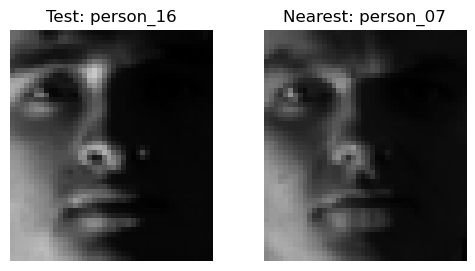

Distance: 2.538 Correct? False


In [32]:
sample=9
dist, neighbor=clf.kneighbors(Z_test[sample:sample+1,:k],n_neighbors=1)
idx=int(neighbor[0,0])
fig,axs=plt.subplots(1,2,figsize=(6,3))
axs[0].imshow(X_test[sample].reshape(H,W),cmap='gray',vmin=0,vmax=1)
axs[0].set_title(f'Test: person_{y_test[sample]:02d}')
axs[1].imshow(X_train[idx].reshape(H,W),cmap='gray',vmin=0,vmax=1)
axs[1].set_title(f'Nearest: person_{y_train[idx]:02d}')
for a in axs:a.axis('off')
plt.show()
print('Distance:',round(float(dist[0,0]),3),'Correct?',bool(y_test[sample]==y_train[idx]))

## 16. Recognition accuracy versus the number of PCA components
Use **the same held-out test set** and vary only the number of retained PCA features. More PCs can improve or worsen classification because some components capture nuisance variation (such as lighting).

**Note:** This graph is exploratory. If you choose the best `k` after looking at test accuracy, you should not report that same test result as an unbiased final performance estimate. Use a separate validation set for tuning in rigorous experiments.

---

## 16. PCAの主成分数と顔認識精度
**同じテストセット**を使い、特徴量の数`k`だけを変えます。主成分を増やすと精度が上がる場合も下がる場合もあります。照明などの不要な変動を含むためです。

**注意：** このグラフは学習用の探索です。テスト結果を見て最良の`k`を選んだ場合、その精度を偏りのない最終評価として報告してはいけません。本格的な実験では別の検証セットを使います。

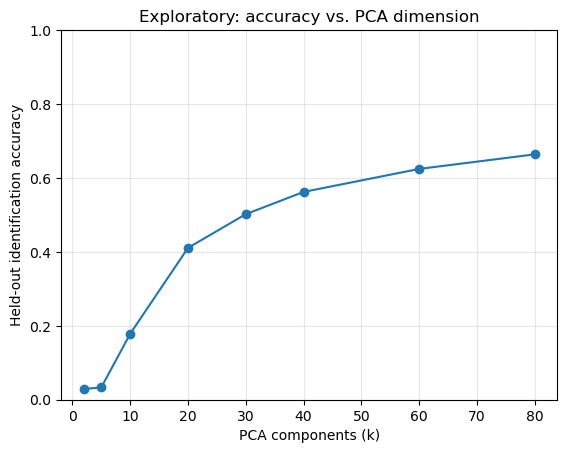

 k  accuracy
 2  0.029046
 5  0.033195
10  0.178423
20  0.410788
30  0.502075
40  0.562241
60  0.624481
80  0.663900


In [33]:
tested_ks=[2,5,10,20,30,40,60,80]
scores=[]
for q in tested_ks:
    model=KNeighborsClassifier(n_neighbors=1)
    model.fit(Z_train[:,:q],y_train)
    scores.append(accuracy_score(y_test,model.predict(Z_test[:,:q])))
plt.plot(tested_ks,scores,'o-');plt.xlabel('PCA components (k)');plt.ylabel('Held-out identification accuracy')
plt.ylim(0,1);plt.grid(alpha=.3);plt.title('Exploratory: accuracy vs. PCA dimension');plt.show()
print(pd.DataFrame({'k':tested_ks,'accuracy':scores}).to_string(index=False))

## 17. Confusion matrix and failure examples
A **confusion matrix** compares true labels (rows) and predicted labels (columns). Values on the diagonal are correct predictions. We also display several errors, which are useful for discussing challenging illumination and limitations of PCA.

---

## 17. 混同行列と失敗例
**混同行列**は正解ラベル（行）と予測ラベル（列）を比較します。対角成分は正解した画像数です。誤認識の例を表示し、照明の難しさやPCAの限界を考えます。

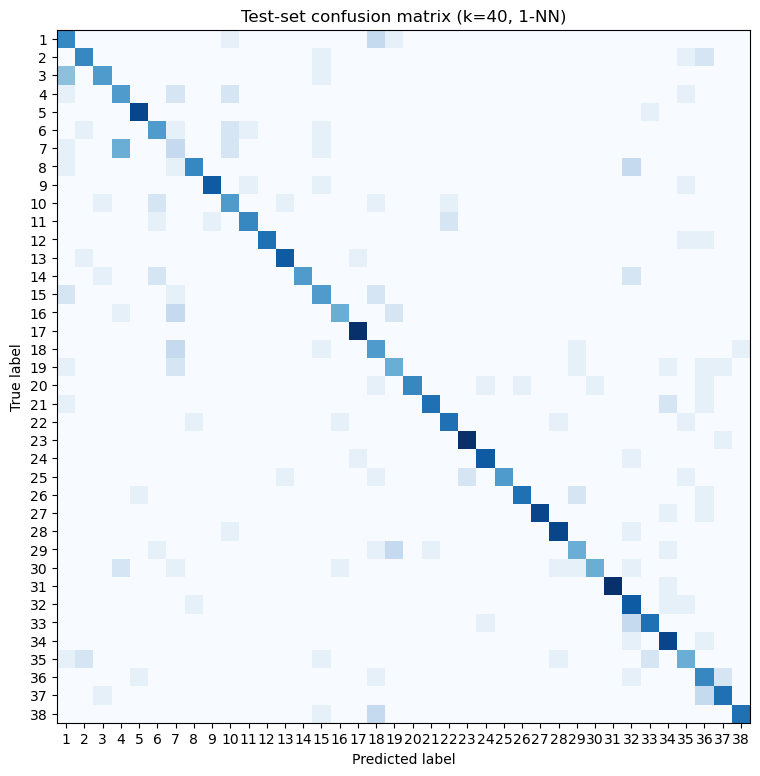

Number of misclassified test images: 162


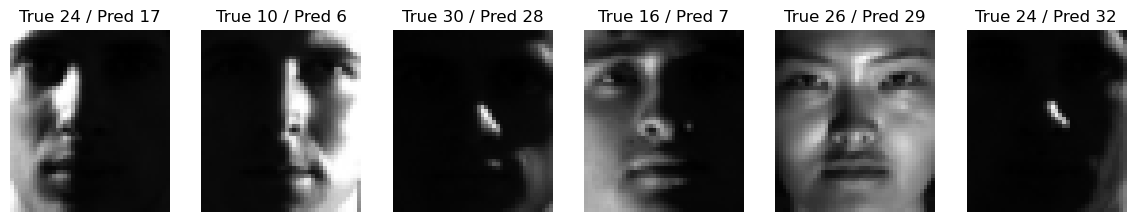

In [34]:
fig,ax=plt.subplots(figsize=(10,9))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,ax=ax,include_values=False,cmap='Blues',colorbar=False)
ax.set_title('Test-set confusion matrix (k=40, 1-NN)');plt.show()
errors=np.flatnonzero(y_pred!=y_test)
print('Number of misclassified test images:',len(errors))
if len(errors):
    selected=errors[:min(6,len(errors))]
    fig,axs=plt.subplots(1,len(selected),figsize=(2.4*len(selected),3))
    for ax,i in zip(np.atleast_1d(axs),selected):
        ax.imshow(X_test[i].reshape(H,W),cmap='gray',vmin=0,vmax=1)
        ax.set_title(f'True {y_test[i]} / Pred {y_pred[i]}');ax.axis('off')
    plt.show()

## 18. NEW: An unregistered person (open-set concept)
Suppose we **remove person 38 from the registered database**, fit a fresh PCA model to people 1–37 only, and then present a person-38 face. A basic 1-NN classifier still returns one of persons 1–37. This illustrates why nearest-neighbor classification alone cannot detect unknown people.

We compare distances for known test faces versus unknown faces; a larger distance is **not always** proof of an unknown identity.

---

## 18. 追加：未登録人物（オープンセットの考え方）
**人物38を登録データから除き**、人物1～37だけでPCAと分類器を学習します。その後、人物38の顔を入力します。通常の1-NNはそれでも人物1～37の誰かを返します。これにより、最近傍分類だけでは未登録人物を検出できないことが分かります。

既知画像と未知画像の距離を比較しますが、距離が大きいだけで未知人物と断定できるわけではありません。

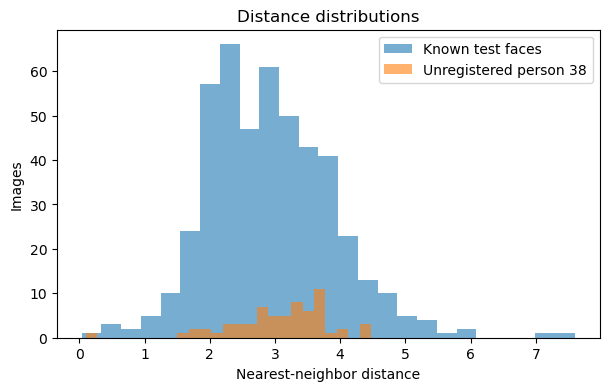

Forced label for one person-38 image: 7


In [35]:
known_mask = y_all!=38
known_idx=np.flatnonzero(known_mask)
known_train_i,known_test_i=train_test_split(known_idx,test_size=.2,random_state=SEED,stratify=y_all[known_idx])
unknown_i=np.flatnonzero(~known_mask)
pca_open=PCA(n_components=40,svd_solver='randomized',random_state=SEED)
Z_known_train=pca_open.fit_transform(X_all[known_train_i])
Z_known_test=pca_open.transform(X_all[known_test_i]);Z_unknown=pca_open.transform(X_all[unknown_i])
matcher=KNeighborsClassifier(n_neighbors=1).fit(Z_known_train,y_all[known_train_i])
d_known,_=matcher.kneighbors(Z_known_test); d_unknown,_=matcher.kneighbors(Z_unknown)
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(d_known.ravel(),bins=25,alpha=.6,label='Known test faces')
ax.hist(d_unknown.ravel(),bins=25,alpha=.6,label='Unregistered person 38')
ax.set_xlabel('Nearest-neighbor distance');ax.set_ylabel('Images');ax.legend();ax.set_title('Distance distributions');plt.show()
print('Forced label for one person-38 image:',matcher.predict(Z_unknown[:1])[0])

## 19. A simple rejection threshold (teaching illustration only)
If the minimum PCA distance exceeds a threshold `τ`, label the image **Unknown**. We choose `τ` from the **training-gallery nearest-other-image distances** as a simple illustration, not as a calibrated security decision. Training neighbors can be unusually close, so this threshold is not guaranteed to generalize.

$$\widehat{y}=\begin{cases}y_{i^*}, & d_{\min}\le\tau\\\text{Unknown}, & d_{\min}>\tau.\end{cases}$$

---

## 19. しきい値による「未知」の判定（授業用の例）
最小のPCA距離がしきい値`τ`より大きければ**Unknown（未登録）**と判定します。ここでは**学習画像同士の最近傍距離**から説明用の`τ`を決めますが、安全性を保証する調整済みの判定法ではありません。学習画像の距離は過度に小さくなることがあり、未知データには一般化しない場合があります。

In [36]:
train_neighbor_dist,_=matcher.kneighbors(Z_known_train,n_neighbors=2)
tau=float(np.quantile(train_neighbor_dist[:,1],0.95))
known_reject=(d_known.ravel()>tau).mean()
unknown_reject=(d_unknown.ravel()>tau).mean()
print('Illustrative threshold τ:',round(tau,3))
print('Known faces rejected (false rejects):',round(float(known_reject),3))
print('Unknown person 38 rejected:',round(float(unknown_reject),3))

Illustrative threshold τ: 4.548
Known faces rejected (false rejects): 0.053
Unknown person 38 rejected: 0.0


**Research caution:** For a meaningful open-set evaluation, tune `τ` using separate validation people and evaluate on **different unseen identities**. Threshold choice, camera conditions, and skin-tone/lighting balance can all affect results. This introductory demo is not suitable for deployment.

---

**研究上の注意：** 実際の未知人物判定では、別の人物からなる検証データで`τ`を決め、さらに**異なる未知人物**で評価する必要があります。しきい値、撮影環境、照明や被写体の条件で結果は変わります。この入門例を実環境の認証に使わないでください。

## 20. Why recognition fails: lighting, alignment, and PCA limitations
PCA finds directions of **large image variation**, not necessarily directions that best separate identity. Lighting changes, image position, expression, pose, and background may dominate. This dataset consists of controlled face images, so accuracy here does not predict real-world performance. Modern face recognition usually uses learned deep features instead.

**Privacy:** The dataset is for teaching; avoid publishing face photos or inferred identities without appropriate permission.

---

## 20. 認識が失敗する理由：照明、位置合わせ、PCAの限界
PCAは**画像のばらつきが大きい方向**を探しますが、その方向が人物を最もよく区別するとは限りません。照明、顔の位置、表情、姿勢、背景が影響します。このデータセットは制御された条件の画像なので、実環境の性能を表すものではありません。現在の顔認識では深層学習で得た特徴量もよく使われます。

**プライバシー：** 教育用データとして利用し、許可なく顔写真や個人情報を公開しないでください。

## 21. Student exercises / 学生演習
**Exercise A (basic):** Change `H, W` to `32, 28`. What happens to computation and reconstruction?

**Exercise B (intermediate):** Compare 1-NN with 3-NN. Does the accuracy improve?

**Exercise C (intermediate):** Use only 2 Eigenfaces to reconstruct a face. Explain the visible differences.

**Exercise D (advanced):** Make a three-way training/validation/test split so that `k` is selected using validation accuracy and reported once on the untouched test set.

**Exercise E (discussion):** Why is person-38 reconstruction possible even if person-38 identification is not?

---

## 21. 学生演習
**演習A（基本）：** `H, W`を`32, 28`に変更します。計算量と再構成結果はどう変わりますか？

**演習B（中級）：** 1-NNと3-NNを比較し、認識精度を確認します。

**演習C（中級）：** 固有顔を2個だけ使って再構成し、違いを説明します。

**演習D（発展）：** 学習・検証・テストの3つに分割し、検証データで`k`を選んでから、触れていないテストデータで1回だけ評価します。

**演習E（考察）：** 人物38の顔は再構成できるのに、人物38と識別できないのはなぜでしょうか？

## 22. Summary and symbol glossary
| Symbol | Meaning | 日本語 |
|---|---|---|
| `x` | vectorized face | ベクトル化した顔画像 |
| `μ` | mean face | 平均顔 |
| `U_k` | first `k` Eigenfaces (column convention) | 最初のk個の固有顔 |
| `Σ` | singular-value matrix | 特異値行列 |
| `z` | PCA feature coordinates | PCA特徴座標 |
| `k` | retained components | 残す主成分の数 |
| `d` | Euclidean distance | ユークリッド距離 |
| `τ` | rejection threshold | 拒否のしきい値 |

**What to remember:** Image → subtract mean → PCA/SVD → features → nearest neighbor → predicted person → evaluate. **Reconstruction is not recognition.**

---

## 22. まとめ
画像 → 平均を引く → PCA/SVD → 特徴ベクトル → 最近傍照合 → 人物を予測 → 評価、という流れを覚えましょう。**画像の再構成と人物の識別は異なる課題です。**

**教科書：** Brunton & Kutz, *Data-Driven Science and Engineering*, §1.5–1.6, pp. 27–40。PCAと固有顔の基本例は教科書に沿っています。最近傍分類・データ分割・性能評価・未登録人物の拒否は追加演習です。